# Bài tập 3 - Phân tích khám phá dữ liệu thuê nhà tại TP.HCM

**Câu hỏi nghiên cứu:** Giá thuê và đơn giá thuê khác nhau như thế nào theo loại hình, khu vực, diện tích và tiện ích? Những khác biệt này gợi ý quyết định gì cho sinh viên, chủ nhà và nền tảng đăng tin?

Phân tích sử dụng dữ liệu CafeLand đã làm giàu và bộ gold đã chuẩn hóa. Giá thuê tính bằng triệu VNĐ/tháng; đơn giá tính bằng nghìn VNĐ/m²/tháng. Kết quả mô tả tin đăng thu thập được, không đại diện cho giá giao dịch hay toàn bộ nguồn cung thị trường.

## 1. Phạm vi và phương pháp

Phân tích gồm kiểm tra cấu trúc và độ đầy đủ; đối chiếu raw với gold theo ID; mô tả quy tắc lọc và điền thiếu; rà ngoại lai theo từng loại hình; sau đó phân tích giá, diện tích, phân khúc, địa bàn và tiện ích.

Gold là tập dữ liệu cleaned chính. Raw được dùng để kiểm tra nguồn gốc đặc trưng và phân tích tiện ích được khai báo rõ. Giá trị được điền theo quy tắc nghiệp vụ không được xem như quan sát xác nhận.

In [1]:
from pathlib import Path
import json, re, shutil, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"

DATA = Path(r"C:\dap")
RAW_PATH = DATA / "raw_cafeland_thue_summary_20000_enriched.csv"
GOLD_PATH = DATA / "gold_student_rental_train_from_20000.csv"
JSON_PATH = DATA / "gold_student_rental_train_from_20000.json"
SRC = Path(r"C:\dap\DAP26-main\src")
sys.path.insert(0, str(SRC))
from standardize_data import NON_HCM_PROVINCES, parse_rental_price, parse_area
from standardize_data import extract_district, categorize_student_property

# Khi mở notebook tại thư mục bàn giao, CSV cleaned được lưu cạnh notebook.
OUT_DIR = Path.cwd()
CLEAN_PATH = OUT_DIR / "gold_student_rental_cleaned_eda.csv"
assert RAW_PATH.exists() and GOLD_PATH.exists() and JSON_PATH.exists()

## 2. Nạp dữ liệu và kiểm tra ghép nối

ID của gold được đối chiếu với row_id trong raw. URL được kiểm tra để xác nhận mỗi tin được ghép đúng trước khi phân tích các trường của hai nguồn.

In [2]:
raw = pd.read_csv(RAW_PATH, encoding="utf-8-sig", dtype=str, keep_default_na=False)
gold = pd.read_csv(GOLD_PATH, encoding="utf-8-sig", dtype={"url": str})
gold_columns = gold.columns.tolist()
with JSON_PATH.open(encoding="utf-8") as f:
    gold_json = json.load(f)
metadata = gold_json.get("metadata", {})
stats_json = metadata.get("summary_statistics", {})

raw["row_id_num"] = pd.to_numeric(raw["row_id"], errors="coerce").astype("Int64")
gold["id_num"] = pd.to_numeric(gold["id"], errors="coerce").astype("Int64")
raw_url_by_id = raw.set_index("row_id_num")["url"]
url_matches = gold.apply(lambda r: raw_url_by_id.get(r["id_num"], None) == r["url"], axis=1)
print(f"Raw enriched: {len(raw):,} dòng; gold đã chuẩn hóa: {len(gold):,} dòng")
print(f"Gold JSON records: {len(gold_json.get('records', [])):,}")
print(f"ID/URL khớp: {int(url_matches.sum()):,}/{len(gold):,}")
print(f"URL trùng raw/gold: {int(raw['url'].duplicated().sum()):,}/{int(gold['url'].duplicated().sum()):,}")
assert url_matches.all(), "ID/URL không khớp, dừng ghép dữ liệu."
assert len(gold_json.get("records", [])) == len(gold)
merged = gold.merge(raw, left_on="id_num", right_on="row_id_num", validate="one_to_one",
                    suffixes=("_gold", "_raw"))
labels = {"phong_tro_ktx": "Phòng trọ / KTX", "can_ho": "Căn hộ", "nha_nguyen_can": "Nhà nguyên căn"}

Raw enriched: 20,000 dòng; gold đã chuẩn hóa: 16,338 dòng
Gold JSON records: 16,338
ID/URL khớp: 16,338/16,338
URL trùng raw/gold: 0/0


## 3. Chất lượng dữ liệu và giá trị thiếu

Raw thể hiện thông tin thu thập ban đầu; gold có thể đã được điền giá trị theo quy tắc nghiệp vụ. Các bảng dưới đây phân biệt dữ liệu chưa được cung cấp với giá trị đã có trong tập chuẩn hóa. Giá trị tiện ích trống trong raw không đồng nghĩa tiện ích không có.

In [3]:
def blank_count(s):
    return s.astype(str).str.strip().eq("").sum()

raw_source = raw.drop(columns=["row_id_num"], errors="ignore")
raw_missing = pd.DataFrame({"Số trống": raw_source.apply(blank_count)})
raw_missing["Tỷ lệ trống (%)"] = raw_missing["Số trống"] / len(raw) * 100
display(Markdown("**Missingness trong raw enriched**"))
display(raw_missing.sort_values("Tỷ lệ trống (%)", ascending=False).style.format({"Tỷ lệ trống (%)": "{:.1f}%"}))
gold_source = gold[gold_columns]
gold_missing = pd.DataFrame({"Số trống gold": gold_source.apply(blank_count)})
gold_missing["Tỷ lệ trống gold (%)"] = gold_missing["Số trống gold"] / len(gold) * 100
display(Markdown("**Missingness trong gold CSV để đối chiếu**"))
display(gold_missing.style.format({"Tỷ lệ trống gold (%)": "{:.1f}%"}))
print("Cờ xử lý raw:", raw["parsing_flag"].value_counts().to_dict())
print("Loại hình:", gold["property_type"].value_counts().to_dict())
print("Quận/huyện Khác:", int(gold["quan_huyen"].eq("Khác").sum()))

feature_cols = ["so_phong_ngu", "so_toilet", "has_wc_rieng", "has_gac_lung",
                "has_may_lanh", "gio_tu_do", "cho_nau_an", "is_full_furniture"]
coverage_rows = []
for col in feature_cols:
    raw_values = merged[f"{col}_raw"].astype(str).str.strip()
    source_num = pd.to_numeric(raw_values.replace("", np.nan), errors="coerce")
    gold_num = pd.to_numeric(merged[f"{col}_gold"], errors="coerce")
    explicit = source_num.notna()
    coverage_rows.append({
        "Đặc trưng": col,
        "Raw chưa có giá trị": int(raw_values.eq("").sum()),
        "Gold có giá trị khi raw trống": int((raw_values.eq("") & gold_num.notna()).sum()),
        "Raw tường minh khác gold": int((explicit & source_num.ne(gold_num)).sum()),
    })
coverage = pd.DataFrame(coverage_rows).set_index("Đặc trưng")
display(Markdown("**Độ phủ raw và các giá trị đã có trong gold**"))
display(coverage)


**Missingness trong raw enriched**

,Số trống,Tỷ lệ trống (%)
has_wc_rieng,19121,95.6%
gio_tu_do,17657,88.3%
cho_nau_an,17259,86.3%
has_may_lanh,16008,80.0%
has_gac_lung,15792,79.0%
is_full_furniture,13725,68.6%
so_toilet,13311,66.6%
so_phong_ngu,4814,24.1%
title_raw,0,0.0%
row_id,0,0.0%


**Missingness trong gold CSV để đối chiếu**

,Số trống gold,Tỷ lệ trống gold (%)
id,0,0.0%
title_raw,0,0.0%
url,0,0.0%
quan_huyen,0,0.0%
tinh_thanh,0,0.0%
property_type,0,0.0%
gia_thue_trieu_thang,0,0.0%
dien_tich_m2,0,0.0%
don_gia_nghin_m2,0,0.0%
so_phong_ngu,0,0.0%


Cờ xử lý raw: {'DONE_REGEX': 15645, 'RESOLVED_LLM': 3889, 'FALLBACK_REGEX': 400, 'SKIP_NON_RENTAL': 66}
Loại hình: {'can_ho': 6562, 'phong_tro_ktx': 6007, 'nha_nguyen_can': 3769}
Quận/huyện Khác: 8659


**Độ phủ raw và các giá trị đã có trong gold**

,Raw chưa có giá trị,Gold có giá trị khi raw trống,Raw tường minh khác gold
Đặc trưng,,,
so_phong_ngu,2256,2256,0
so_toilet,10229,10229,0
has_wc_rieng,15497,15497,14
has_gac_lung,12427,12427,0
has_may_lanh,12640,12640,0
gio_tu_do,14191,14191,0
cho_nau_an,13821,13821,0
is_full_furniture,10574,10574,0


### Quy tắc lọc trong quy trình chuẩn hóa

Các điều kiện lọc được tái lập theo thứ tự của mã chuẩn hóa: giá không phân tích được; giá ngoài 0,5–40 triệu VNĐ/tháng; diện tích thiếu hoặc ngoài 5–350 m²; địa điểm ngoài TP.HCM; loại hình không thuộc ba phân khúc; cuối cùng là địa chỉ không đủ căn cứ xác nhận TP.HCM. Mỗi dòng chỉ nhận một lý do đầu tiên để số lượng không bị cộng trùng.

Đây là ngưỡng nghiệp vụ của bộ dữ liệu thuê nhà sinh viên, không chứng minh mọi tin ngoài khoảng đều sai. Số ID được giữ lại sẽ được đối chiếu với tập gold.

In [4]:
def hcm_marker(location):
    return any(k in str(location).lower() for k in ["hồ chí minh", "tp.hcm", "tphcm", "sài gòn", "hcm"])

def drop_reason(r):
    price = parse_rental_price(r.get("price_raw", ""))
    if price is None:
        return "Thiếu/không phân tích được giá"
    if price < 0.5 or price > 40:
        return "Giá ngoài ngưỡng nghiệp vụ 0,5–40"
    area = parse_area(r.get("area_raw", ""))
    if area is None or area <= 0 or area > 350:
        return "Thiếu/ngoài ngưỡng diện tích 5–350"
    loc = str(r.get("location_raw", ""))
    if any(p in loc.lower() for p in NON_HCM_PROVINCES):
        return "Địa điểm ngoài TP.HCM"
    if categorize_student_property({
        "title_raw": r.get("title_raw", ""),
        "description_raw": r.get("description_raw", ""),
        "property_type_target": r.get("property_type_target", ""),
    }) is None:
        return "Thương mại/xa xỉ/không xác định loại hình"
    if extract_district(loc, r.get("title_raw", "")) == "Khác" and not hcm_marker(loc):
        return "Không đủ căn cứ xác nhận TP.HCM"
    return "Giữ lại trong gold"

raw["quyet_dinh_tai_lap"] = raw.apply(drop_reason, axis=1)
decision_counts = raw["quyet_dinh_tai_lap"].value_counts().rename_axis("Quyết định").reset_index(name="Số dòng")
decision_counts["Tỷ lệ raw (%)"] = decision_counts["Số dòng"] / len(raw) * 100
display(decision_counts.style.format({"Tỷ lệ raw (%)": "{:.2f}%"}))
gold_ids = set(gold["id_num"].astype(int))
recreated_ids = set(raw.loc[raw["quyet_dinh_tai_lap"].eq("Giữ lại trong gold"), "row_id_num"].astype(int))
diff_ids = gold_ids.symmetric_difference(recreated_ids)
print(f"ID chênh giữa tái lập và gold: {len(diff_ids)}")
if diff_ids:
    print("Ví dụ ID cần rà:", sorted(diff_ids)[:20])
else:
    print("Điều kiện tái lập khớp tập gold.")

,Quyết định,Số dòng,Tỷ lệ raw (%)
0,Giữ lại trong gold,16338,81.69%
1,"Giá ngoài ngưỡng nghiệp vụ 0,5–40",2728,13.64%
2,Địa điểm ngoài TP.HCM,512,2.56%
3,Thiếu/ngoài ngưỡng diện tích 5–350,194,0.97%
4,Thương mại/xa xỉ/không xác định loại hình,187,0.94%
5,Thiếu/không phân tích được giá,41,0.21%


ID chênh giữa tái lập và gold: 0
Điều kiện tái lập khớp tập gold.


### Quyết định xử lý và cơ sở lựa chọn

Bảng tóm tắt số dòng chịu ảnh hưởng của từng quy tắc. Gold giữ các giá trị đã được điền theo nghiệp vụ; phân tích tiện ích dùng thêm trạng thái raw được khai báo rõ để tránh nhầm giá trị suy diễn với thông tin xác nhận. Quận/huyện chưa nhận diện được giữ nhãn Khác, không tự gán sang địa bàn khác.

In [5]:
log_rows = []
for _, r in decision_counts.iterrows():
    reason = r["Quyết định"]
    actions = {
        "Giữ lại trong gold": ("Giữ; đánh dấu IQR riêng theo loại hình.",
                               "Đạt điều kiện giá, diện tích, phạm vi và phân khúc."),
        "Thiếu/không phân tích được giá": ("Loại khỏi phân tích giá; giữ raw nguyên trạng.",
                                           "Không có biến mục tiêu định lượng đáng tin cậy."),
        "Giá ngoài ngưỡng nghiệp vụ 0,5–40": ("Loại theo quy tắc gold; rà thêm IQR, không coi là luật phổ quát.",
                                             "Giới hạn nghiệp vụ của AVM thuê sinh viên."),
        "Thiếu/ngoài ngưỡng diện tích 5–350": ("Không suy đoán diện tích; loại khỏi so sánh giá/m².",
                                                "Thiếu diện tích làm sai phân tích không gian."),
        "Địa điểm ngoài TP.HCM": ("Loại khỏi phạm vi nghiên cứu.",
                                  "Đề tài giới hạn TP.HCM."),
        "Thương mại/xa xỉ/không xác định loại hình": ("Loại khỏi ba phân khúc đích.",
                                                       "Không phù hợp thuê ở sinh viên hoặc thiếu căn cứ."),
        "Không đủ căn cứ xác nhận TP.HCM": ("Loại khỏi mẫu chính; không đoán quận.",
                                             "Tránh gán sai địa lý."),
    }
    action, reason_text = actions[reason]
    log_rows.append({"Vấn đề/quyết định": reason, "Số dòng": int(r["Số dòng"]),
                     "Cách xử lý": action, "Lý do": reason_text})

unknown_n = int(gold["quan_huyen"].eq("Khác").sum())
log_rows.append({"Vấn đề/quyết định": "Quận/huyện chưa xác định trong gold", "Số dòng": unknown_n,
                 "Cách xử lý": "Giữ nhãn Khác; không suy đoán; loại khỏi xếp hạng địa bàn chính.",
                 "Lý do": "Tránh đưa kết luận địa lý dựa trên vị trí không chắc chắn."})
features = ["so_phong_ngu", "so_toilet", "has_wc_rieng", "has_gac_lung",
            "has_may_lanh", "gio_tu_do", "cho_nau_an", "is_full_furniture"]
for col in features:
    values = pd.to_numeric(raw[col], errors="coerce")
    invalid = int((values.notna() & ~values.isin([0, 1])).sum()) if col not in ["so_phong_ngu", "so_toilet"] else 0
    if invalid:
        log_rows.append({"Vấn đề/quyết định": f"Mã ngoài miền nhị phân: {col}", "Số dòng": invalid,
                         "Cách xử lý": "Đưa về chưa rõ trong cleaned; giữ nguyên raw.",
                         "Lý do": "Trạng thái tiện ích chỉ chấp nhận 0 hoặc 1."})

imputation_rules = {
    "so_phong_ngu": "Phòng trọ/căn hộ mặc định 1; nhà nguyên căn mặc định 2.",
    "so_toilet": "Phòng trọ suy ra từ WC riêng; căn hộ và nhà nguyên căn mặc định 1.",
    "has_wc_rieng": "Phòng trọ thiếu thông tin mặc định 1; căn hộ và nhà nguyên căn gán 1.",
    "has_gac_lung": "Thiếu thông tin được chuyển thành 0.",
    "has_may_lanh": "Thiếu thông tin được chuyển thành 0.",
    "gio_tu_do": "Thiếu thông tin mặc định 1.",
    "cho_nau_an": "Thiếu thông tin mặc định 1.",
    "is_full_furniture": "Thiếu thông tin được chuyển thành 0.",
}
for col, rule in imputation_rules.items():
    source = merged[f"{col}_raw"].astype(str).str.strip()
    missing_n = int(source.eq("").sum())
    raw_num = pd.to_numeric(source.replace("", np.nan), errors="coerce")
    gold_num = pd.to_numeric(merged[f"{col}_gold"], errors="coerce")
    conflict_n = int((raw_num.notna() & raw_num.ne(gold_num)).sum())
    log_rows.append({
        "Vấn đề/quyết định": f"Điền thiếu: {col}",
        "Số dòng": missing_n,
        "Cách xử lý": rule,
        "Lý do": f"Raw tường minh khác gold: {conflict_n}; raw dùng cho phân tích trạng thái đã ghi nhận.",
    })

processing_log = pd.DataFrame(log_rows)
display(processing_log)

,Vấn đề/quyết định,Số dòng,Cách xử lý,Lý do
0,Giữ lại trong gold,16338,Giữ; đánh dấu IQR riêng theo loại hình.,"Đạt điều kiện giá, diện tích, phạm vi và phân khúc."
1,"Giá ngoài ngưỡng nghiệp vụ 0,5–40",2728,"Loại theo quy tắc gold; rà thêm IQR, không coi là luật phổ quát.",Giới hạn nghiệp vụ của AVM thuê sinh viên.
2,Địa điểm ngoài TP.HCM,512,Loại khỏi phạm vi nghiên cứu.,Đề tài giới hạn TP.HCM.
3,Thiếu/ngoài ngưỡng diện tích 5–350,194,Không suy đoán diện tích; loại khỏi so sánh giá/m².,Thiếu diện tích làm sai phân tích không gian.
4,Thương mại/xa xỉ/không xác định loại hình,187,Loại khỏi ba phân khúc đích.,Không phù hợp thuê ở sinh viên hoặc thiếu căn cứ.
5,Thiếu/không phân tích được giá,41,Loại khỏi phân tích giá; giữ raw nguyên trạng.,Không có biến mục tiêu định lượng đáng tin cậy.
6,Quận/huyện chưa xác định trong gold,8659,Giữ nhãn Khác; không suy đoán; loại khỏi xếp hạng địa bàn chính.,Tránh đưa kết luận địa lý dựa trên vị trí không chắc chắn.
7,Mã ngoài miền nhị phân: has_may_lanh,1,Đưa về chưa rõ trong cleaned; giữ nguyên raw.,Trạng thái tiện ích chỉ chấp nhận 0 hoặc 1.
8,Điền thiếu: so_phong_ngu,2256,Phòng trọ/căn hộ mặc định 1; nhà nguyên căn mặc định 2.,Raw tường minh khác gold: 0; raw dùng cho phân tích trạng thái đã ghi nhận.
9,Điền thiếu: so_toilet,10229,Phòng trọ suy ra từ WC riêng; căn hộ và nhà nguyên căn mặc định 1.,Raw tường minh khác gold: 0; raw dùng cho phân tích trạng thái đã ghi nhận.


## 4. Tập cleaned và kiểm tra ngoại lai

Tập cleaned dùng trong báo cáo là chính CSV gold chuẩn hóa: giữ nguyên 18 cột, thứ tự dòng và giá trị. Raw được ghép riêng để kiểm tra độ phủ đặc trưng và phục vụ biểu đồ tiện ích. Cờ IQR được tính theo từng loại hình để nhận diện điểm cần rà soát; ngoại lai không tự động bị xóa.

In [6]:
clean = gold[gold_columns].copy()
shutil.copyfile(GOLD_PATH, CLEAN_PATH)
clean_copy = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", dtype={"url": str})
pd.testing.assert_frame_equal(clean, clean_copy, check_dtype=True, check_exact=True)
assert clean.columns.tolist() == gold_columns
assert len(clean) == len(gold)

# Bảng EDA giữ dữ liệu gold và ghép riêng các trường quan sát trong raw.
eda = clean.copy()
eda["loai_hinh"] = eda["property_type"].map(labels).fillna(eda["property_type"])
eda["date_raw"] = merged["date_raw"].to_numpy()
eda["location_raw"] = merged["location_raw"].to_numpy()
eda["source_flag_raw"] = merged["parsing_flag"].to_numpy()
feature_cols = ["so_phong_ngu", "so_toilet", "has_wc_rieng", "has_gac_lung",
                "has_may_lanh", "gio_tu_do", "cho_nau_an", "is_full_furniture"]
for col in feature_cols:
    values = pd.to_numeric(merged[f"{col}_raw"], errors="coerce")
    if col not in ["so_phong_ngu", "so_toilet"]:
        values = values.where(values.isin([0, 1]))
    eda[f"{col}_raw_observed"] = values

def iqr_mask(s):
    x = pd.to_numeric(s, errors="coerce")
    valid = x.dropna()
    if len(valid) < 8:
        return pd.Series(False, index=s.index)
    q1, q3 = valid.quantile([.25, .75])
    spread = q3 - q1
    if spread == 0:
        return pd.Series(False, index=s.index)
    return (x < q1 - 1.5 * spread) | (x > q3 + 1.5 * spread)

for flag, col in [("gia_iqr_flag", "gia_thue_trieu_thang"),
                  ("dien_tich_iqr_flag", "dien_tich_m2"),
                  ("don_gia_iqr_flag", "don_gia_nghin_m2")]:
    eda[flag] = False
    for _, idx in eda.groupby("property_type").groups.items():
        eda.loc[idx, flag] = iqr_mask(eda.loc[idx, col])

print(f"Số tin cleaned: {len(clean):,}; số cột: {len(clean.columns)}")
print(f"CSV cleaned khớp gold theo từng ô dữ liệu: {CLEAN_PATH}")
print(f"Quận/huyện Khác: {int(clean['quan_huyen'].eq('Khác').sum()):,} "
      f"({clean['quan_huyen'].eq('Khác').mean():.1%})")
display(eda.groupby("loai_hinh").agg(
    so_mau=("id", "size"),
    gia_iqr=("gia_iqr_flag", "sum"),
    dien_tich_iqr=("dien_tich_iqr_flag", "sum"),
    don_gia_iqr=("don_gia_iqr_flag", "sum"),
))
display(clean[["gia_thue_trieu_thang", "dien_tich_m2", "don_gia_nghin_m2",
               "so_phong_ngu", "so_toilet"]].describe(
                   percentiles=[.25, .5, .75, .9]).T.style.format("{:,.2f}"))

Số tin cleaned: 16,338; số cột: 18
CSV cleaned khớp gold theo từng ô dữ liệu: C:\dap\ex_w3\gold_student_rental_cleaned_eda.csv
Quận/huyện Khác: 8,659 (53.0%)


,so_mau,gia_iqr,dien_tich_iqr,don_gia_iqr
loai_hinh,,,,
Căn hộ,6562,214,136,139
Nhà nguyên căn,3769,0,302,142
Phòng trọ / KTX,6007,398,505,414


,count,mean,std,min,25%,50%,75%,90%,max
gia_thue_trieu_thang,"16,338.00",11.69,8.90,0.75,4.60,9.00,16.00,25.00,40.00
dien_tich_m2,"16,338.00",59.95,40.30,5.00,30.00,53.00,80.00,100.00,350.00
don_gia_nghin_m2,"16,338.00",200.09,105.69,7.00,131.94,177.00,240.00,329.11,"1,666.67"
so_phong_ngu,"16,338.00",1.73,0.96,0.00,1.00,2.00,2.00,3.00,22.00
so_toilet,"16,338.00",1.40,0.81,0.00,1.00,1.00,2.00,2.00,13.00


## 5. Kết quả EDA và diễn giải kinh doanh

Các phần dưới đây phân tích phân bố giá, diện tích, phân khúc, địa bàn, tiện ích và độ đầy đủ thông tin.

### Biểu đồ 1 - Tỷ lệ thiếu thông tin của các đặc trưng

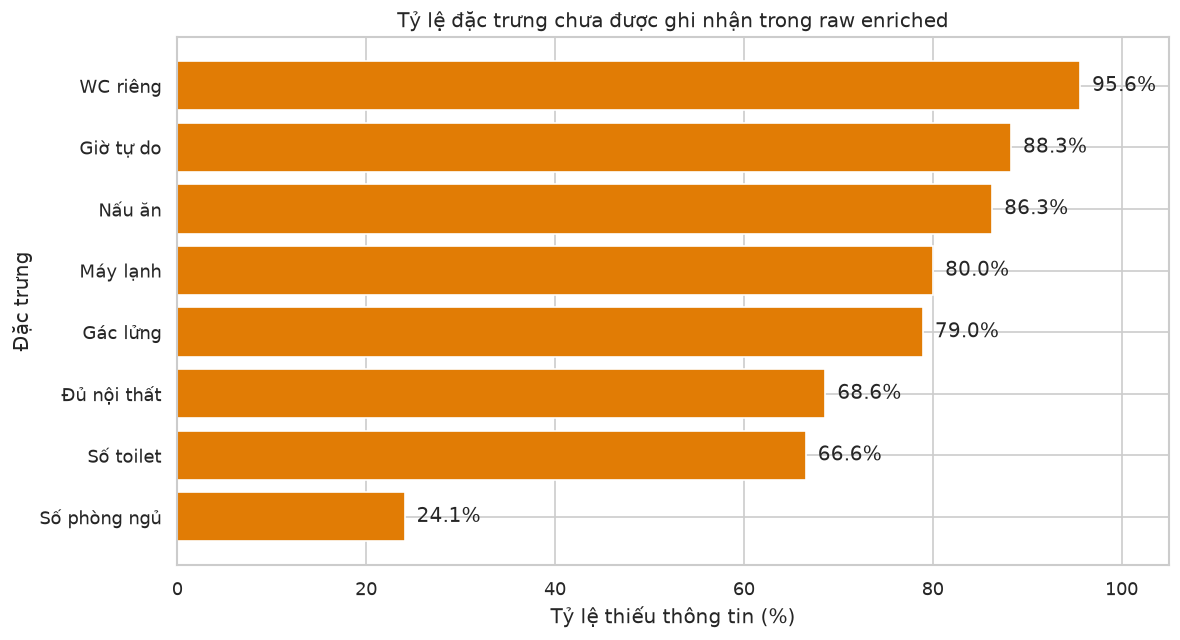

Trong 20,000 tin raw, trường WC riêng thiếu ở 95.6% và Giờ tự do thiếu ở 88.3%. Đây là thông tin chưa được ghi nhận, không có nghĩa các phòng không có đặc điểm đó. Với sinh viên, thiếu thông tin làm tăng thời gian liên hệ và xác minh; nền tảng có thể cải thiện biểu mẫu và nhắc người đăng bổ sung tiện ích có giá trị; chủ nhà khai báo đầy đủ giúp khách sàng lọc nhanh hơn. Vì gold đã điền mặc định một số trường, phân tích và mô hình cần phân biệt giá trị quan sát với giá trị suy diễn để không đánh giá quá cao độ chắc chắn dữ liệu.

In [7]:

missing_features = ["so_phong_ngu", "so_toilet", "has_wc_rieng", "has_gac_lung",
                    "has_may_lanh", "gio_tu_do", "cho_nau_an", "is_full_furniture"]
missing_labels = {
    "so_phong_ngu": "Số phòng ngủ", "so_toilet": "Số toilet",
    "has_wc_rieng": "WC riêng", "has_gac_lung": "Gác lửng",
    "has_may_lanh": "Máy lạnh", "gio_tu_do": "Giờ tự do",
    "cho_nau_an": "Nấu ăn", "is_full_furniture": "Đủ nội thất",
}
missing_rate = raw[missing_features].apply(
    lambda s: s.astype(str).str.strip().eq("").mean() * 100
).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([missing_labels[x] for x in missing_rate.index], missing_rate.values, color="#E17C05")
for y, value in enumerate(missing_rate.values):
    ax.text(value, y, f"  {value:.1f}%", va="center")
ax.set(title="Tỷ lệ đặc trưng chưa được ghi nhận trong raw enriched",
       xlabel="Tỷ lệ thiếu thông tin (%)", ylabel="Đặc trưng")
ax.set_xlim(0, min(105, max(missing_rate.max() * 1.12, 10)))
plt.tight_layout()
plt.show()
top_missing, second_missing = missing_rate.index[-1], missing_rate.index[-2]
display(Markdown(
    f"Trong {len(raw):,} tin raw, trường {missing_labels[top_missing]} thiếu ở "
    f"{missing_rate[top_missing]:.1f}% và {missing_labels[second_missing]} thiếu ở "
    f"{missing_rate[second_missing]:.1f}%. Đây là thông tin chưa được ghi nhận, không có nghĩa các phòng "
    f"không có đặc điểm đó. Với sinh viên, thiếu thông tin làm tăng thời gian liên hệ và xác minh; nền tảng "
    f"có thể cải thiện biểu mẫu và nhắc người đăng bổ sung tiện ích có giá trị; chủ nhà khai báo đầy đủ giúp "
    f"khách sàng lọc nhanh hơn. Vì gold đã điền mặc định một số trường, phân tích và mô hình cần phân biệt "
    f"giá trị quan sát với giá trị suy diễn để không đánh giá quá cao độ chắc chắn dữ liệu."
))


### Biểu đồ 2 - Phân bố giá thuê tháng

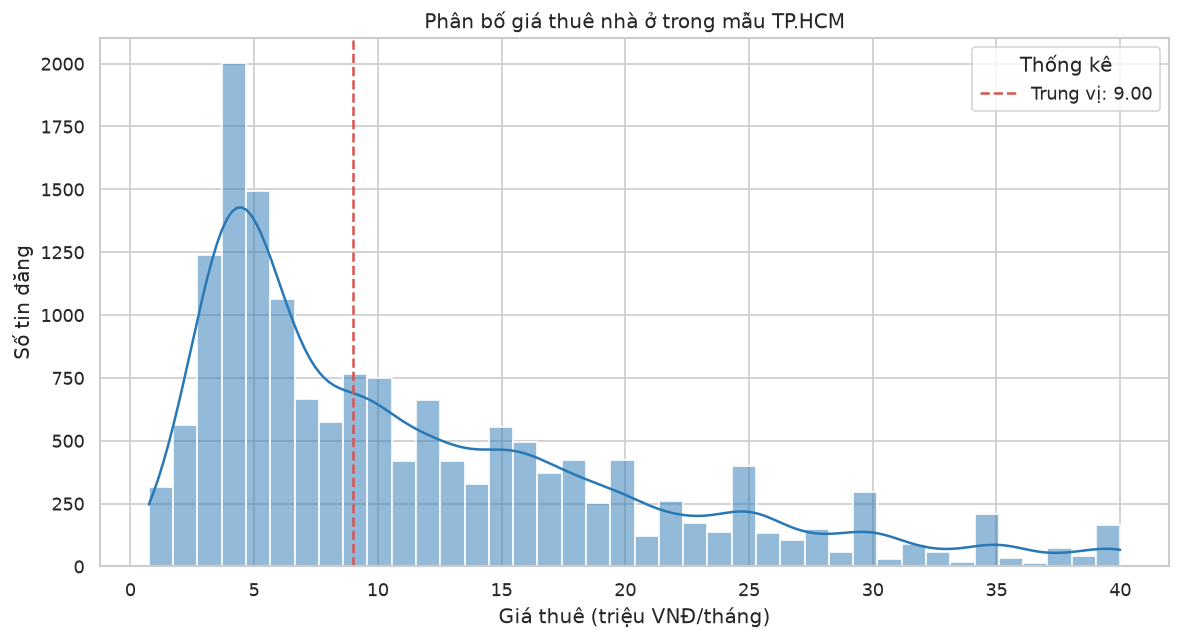

Trong 16,338 tin hợp lệ, giá trung vị là **9.00 triệu VNĐ/tháng**, trung bình 11.69; 50% tin nằm trong 4.60–16.00 triệu và phân vị 90 là 25.00 triệu. Chênh lệch giữa trung bình và trung vị cho thấy một nhóm giá cao có thể kéo bình quân lên, vì vậy sinh viên nên xem trung vị và khoảng phân vị khi đặt ngân sách thay vì coi giá trung bình là mức phổ biến. Chủ nhà có thể định vị giá trong dải cùng phân khúc, còn nền tảng có thể thiết kế bộ lọc ngân sách theo các ngưỡng có nhiều tin. 30.0% tin có giá không quá 5 triệu, nhưng thống kê toàn mẫu trộn nhiều loại hình và quận nên không đảm bảo mức đó có sẵn trong khu vực cụ thể.

In [8]:
x = eda["gia_thue_trieu_thang"].dropna()
med, mean, q1, q3, p90 = x.median(), x.mean(), x.quantile(.25), x.quantile(.75), x.quantile(.90)
share_low = (x <= 5).mean()
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(x, bins=40, kde=True, color="#2878B5", ax=ax)
ax.axvline(med, color="#D9534F", linestyle="--", label=f"Trung vị: {med:.2f}")
ax.set(title="Phân bố giá thuê nhà ở trong mẫu TP.HCM",
       xlabel="Giá thuê (triệu VNĐ/tháng)", ylabel="Số tin đăng")
ax.legend(title="Thống kê")
plt.tight_layout()
plt.show()
display(Markdown(
    f"Trong {len(x):,} tin hợp lệ, giá trung vị là **{med:.2f} triệu VNĐ/tháng**, trung bình {mean:.2f}; "
    f"50% tin nằm trong {q1:.2f}–{q3:.2f} triệu và phân vị 90 là {p90:.2f} triệu. Chênh lệch giữa trung bình "
    f"và trung vị cho thấy một nhóm giá cao có thể kéo bình quân lên, vì vậy sinh viên nên xem trung vị và khoảng "
    f"phân vị khi đặt ngân sách thay vì coi giá trung bình là mức phổ biến. Chủ nhà có thể định vị giá trong dải "
    f"cùng phân khúc, còn nền tảng có thể thiết kế bộ lọc ngân sách theo các ngưỡng có nhiều tin. {share_low:.1%} "
    f"tin có giá không quá 5 triệu, nhưng thống kê toàn mẫu trộn nhiều loại hình và quận nên không đảm bảo mức đó "
    f"có sẵn trong khu vực cụ thể."
))

### Biểu đồ 3 - Phân bố diện tích theo loại hình

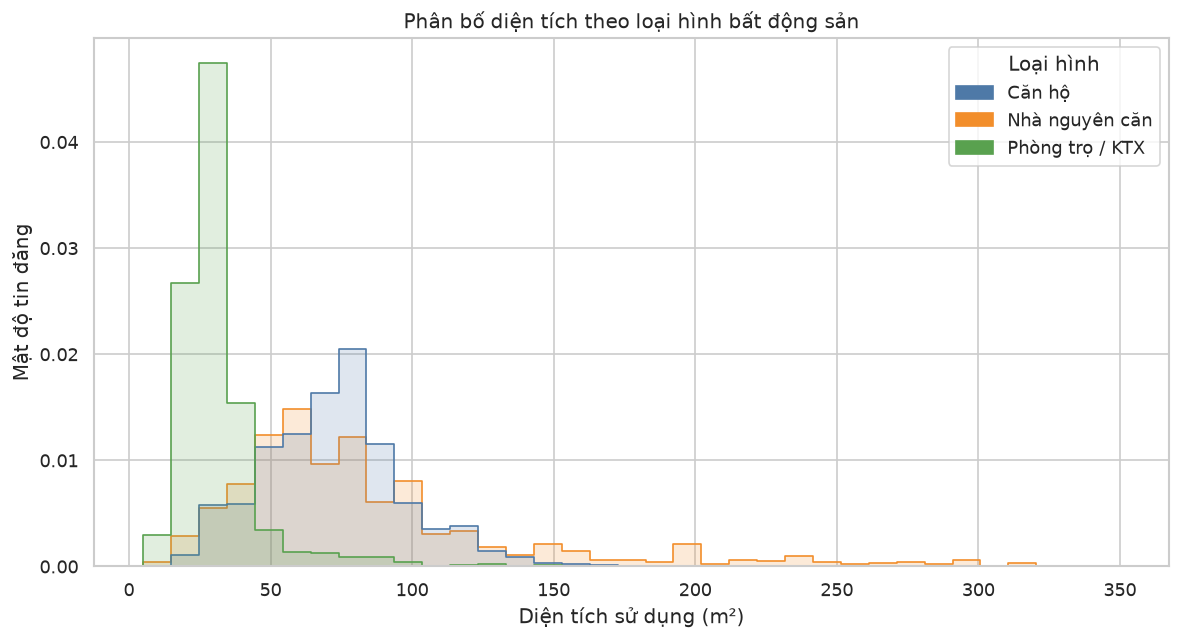

Diện tích trung vị lần lượt là Căn hộ: trung vị 72.0 m² (n=6,562); Nhà nguyên căn: trung vị 72.0 m² (n=3,769); Phòng trọ / KTX: trung vị 25.0 m² (n=6,007). Nhóm **Căn hộ** có diện tích trung vị cao nhất; điều này giúp sinh viên so sánh những lựa chọn cùng loại hình thay vì đặt một phòng nhỏ cạnh nhà nguyên căn rồi chỉ nhìn giá tổng. Chủ nhà có thể xác định khách hàng mục tiêu và mô tả diện tích tương ứng; nền tảng có thể đưa bộ lọc diện tích theo loại hình. Diện tích trong tin là thông tin do người đăng cung cấp, có thể không phản ánh diện tích sử dụng hữu ích, nhất là phòng có gác, nên cần xác minh khi xem nhà.

In [9]:
area_palette = {"Căn hộ":"#4E79A7", "Nhà nguyên căn":"#F28E2B", "Phòng trọ / KTX":"#59A14F"}
ast = eda.groupby("loai_hinh")["dien_tich_m2"].agg(n="count", median="median",
                                                     q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75))
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(data=eda, x="dien_tich_m2", hue="loai_hinh", bins=35, element="step",
             stat="density", common_norm=False, palette=area_palette, alpha=.18, ax=ax)
ax.set(title="Phân bố diện tích theo loại hình bất động sản",
       xlabel="Diện tích sử dụng (m²)", ylabel="Mật độ tin đăng")
ax.legend(handles=[Patch(color=c, label=k) for k,c in area_palette.items()], title="Loại hình")
plt.tight_layout()
plt.show()
summary = "; ".join(f"{k}: trung vị {r['median']:.1f} m² (n={int(r['n']):,})" for k,r in ast.iterrows())
largest = ast["median"].idxmax()
display(Markdown(
    f"Diện tích trung vị lần lượt là {summary}. Nhóm **{largest}** có diện tích trung vị cao nhất; điều này giúp "
    f"sinh viên so sánh những lựa chọn cùng loại hình thay vì đặt một phòng nhỏ cạnh nhà nguyên căn rồi chỉ nhìn "
    f"giá tổng. Chủ nhà có thể xác định khách hàng mục tiêu và mô tả diện tích tương ứng; nền tảng có thể đưa bộ lọc "
    f"diện tích theo loại hình. Diện tích trong tin là thông tin do người đăng cung cấp, có thể không phản ánh diện "
    f"tích sử dụng hữu ích, nhất là phòng có gác, nên cần xác minh khi xem nhà."
))

### Biểu đồ 4 - Giá thuê theo loại hình

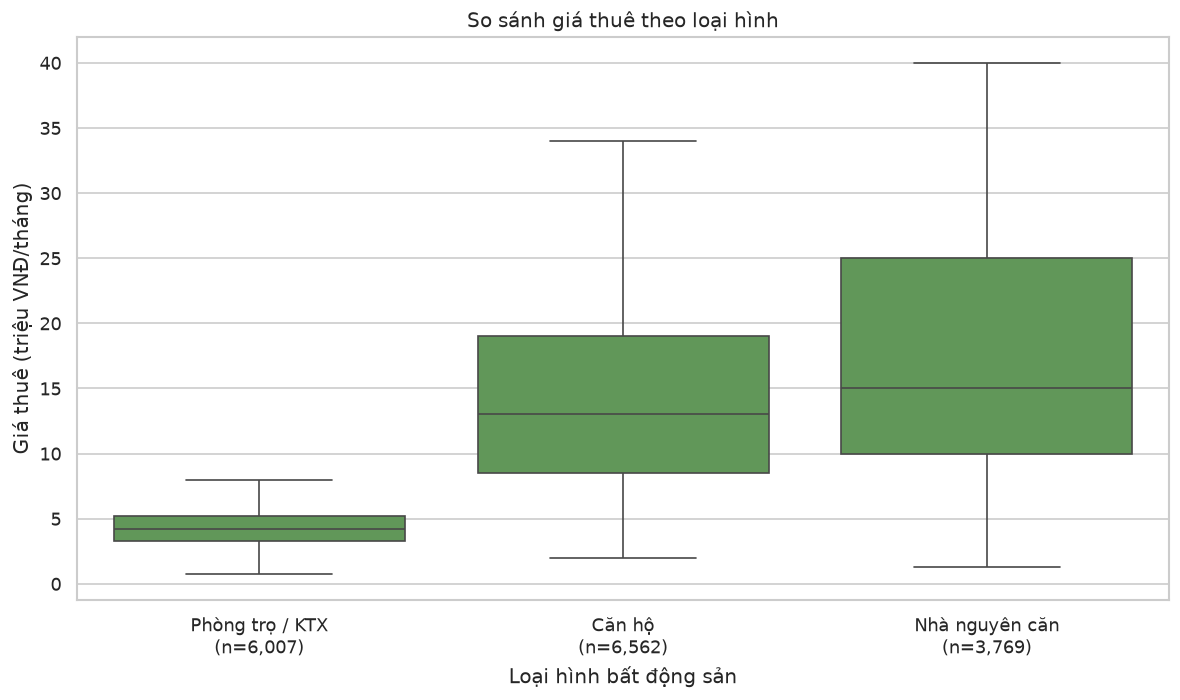

Phòng trọ / KTX: trung vị 4.20, P90 7.00 triệu; Căn hộ: trung vị 13.00, P90 26.00 triệu; Nhà nguyên căn: trung vị 15.00, P90 32.00 triệu. Trung vị giữa nhóm cao nhất (**Nhà nguyên căn**) và thấp nhất (**Phòng trọ / KTX**) chênh 10.80 triệu/tháng. Với sinh viên, phân tích này làm rõ sự đánh đổi giữa ngân sách, riêng tư và diện tích; chủ nhà nên so sánh giá với đúng loại sản phẩm; nền tảng nên phân loại tin để mức tham chiếu không trộn các thị trường khác nhau. Boxplot ẩn các điểm xa để thân hộp dễ đọc nhưng P90 được báo riêng; đây là so sánh mô tả, chưa kiểm soát vị trí, chất lượng và nội thất.

In [10]:
order = eda.groupby("loai_hinh")["gia_thue_trieu_thang"].median().sort_values().index.tolist()
tstats = eda.groupby("loai_hinh")["gia_thue_trieu_thang"].agg(
    n="count", median="median", mean="mean", p90=lambda s:s.quantile(.9)).reindex(order)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=eda, x="loai_hinh", y="gia_thue_trieu_thang", order=order,
            color="#59A14F", showfliers=False, ax=ax)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{k}\n(n={int(tstats.loc[k,'n']):,})" for k in order])
ax.set(title="So sánh giá thuê theo loại hình", xlabel="Loại hình bất động sản",
       ylabel="Giá thuê (triệu VNĐ/tháng)")
plt.tight_layout()
plt.show()
summ = "; ".join(f"{k}: trung vị {r['median']:.2f}, P90 {r['p90']:.2f} triệu" for k,r in tstats.iterrows())
lo, hi = tstats["median"].idxmin(), tstats["median"].idxmax()
display(Markdown(
    f"{summ}. Trung vị giữa nhóm cao nhất (**{hi}**) và thấp nhất (**{lo}**) chênh "
    f"{tstats.loc[hi,'median']-tstats.loc[lo,'median']:.2f} triệu/tháng. Với sinh viên, phân tích này làm rõ "
    f"sự đánh đổi giữa ngân sách, riêng tư và diện tích; chủ nhà nên so sánh giá với đúng loại sản phẩm; nền tảng "
    f"nên phân loại tin để mức tham chiếu không trộn các thị trường khác nhau. Boxplot ẩn các điểm xa để thân hộp "
    f"dễ đọc nhưng P90 được báo riêng; đây là so sánh mô tả, chưa kiểm soát vị trí, chất lượng và nội thất."
))

### Biểu đồ 5 - Đơn giá thuê theo quận/huyện

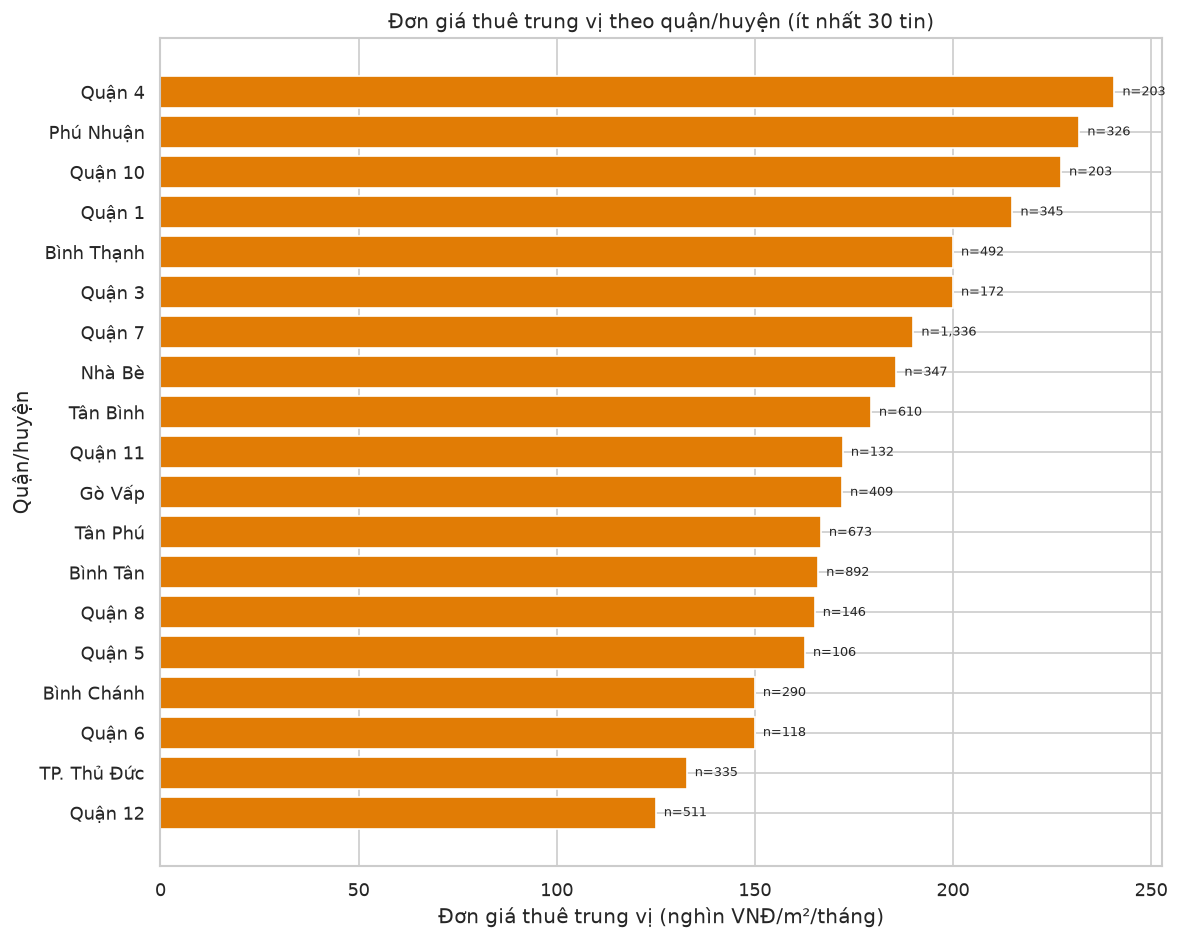

Trong nhóm đủ cỡ mẫu, Quận 4 có đơn giá trung vị cao nhất (240.7 nghìn VNĐ/m²/tháng); Quận 12 thấp nhất (125.0), chênh tương đối 92.6%. Sinh viên có thể cân nhắc khu vực lân cận để đổi đơn giá lấy thời gian đi lại; chủ nhà có thêm mốc so sánh khi định vị sản phẩm; nền tảng có thể gợi ý địa bàn thay thế theo ngân sách. Chỉ địa chỉ đã nhận diện và có ít nhất 30 tin được xếp hạng; 8.659 dòng Khác không nằm trong so sánh, và cơ cấu loại hình/diện tích khác nhau giữa quận nên đơn giá này chưa phải giá chuẩn đã hiệu chỉnh.

In [11]:
dp = eda.loc[eda["quan_huyen"].ne("Khác")].groupby("quan_huyen")["don_gia_nghin_m2"].agg(
    n="count", median="median")
dp = dp[dp["n"] >= 30].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(dp.index, dp["median"], color="#E17C05")
for y, (_, r) in enumerate(dp.iterrows()):
    ax.text(r["median"], y, f"  n={int(r['n']):,}", va="center", fontsize=8)
ax.set(title="Đơn giá thuê trung vị theo quận/huyện (ít nhất 30 tin)",
       xlabel="Đơn giá thuê trung vị (nghìn VNĐ/m²/tháng)", ylabel="Quận/huyện")
plt.tight_layout()
plt.show()
top, bottom = dp["median"].idxmax(), dp["median"].idxmin()
gap = (dp.loc[top,"median"]/dp.loc[bottom,"median"]-1)*100
display(Markdown(
    f"Trong nhóm đủ cỡ mẫu, {top} có đơn giá trung vị cao nhất ({dp.loc[top,'median']:.1f} nghìn VNĐ/m²/tháng); "
    f"{bottom} thấp nhất ({dp.loc[bottom,'median']:.1f}), chênh tương đối {gap:.1f}%. "
    f"Sinh viên có thể cân nhắc khu vực lân cận để đổi đơn giá lấy thời gian đi lại; chủ nhà có thêm mốc so sánh "
    f"khi định vị sản phẩm; nền tảng có thể gợi ý địa bàn thay thế theo ngân sách. Chỉ địa chỉ đã nhận diện và có "
    f"ít nhất 30 tin được xếp hạng; 8.659 dòng Khác không nằm trong so sánh, và cơ cấu loại hình/diện tích khác nhau "
    f"giữa quận nên đơn giá này chưa phải giá chuẩn đã hiệu chỉnh."
))

### Biểu đồ 6 - Diện tích và giá thuê

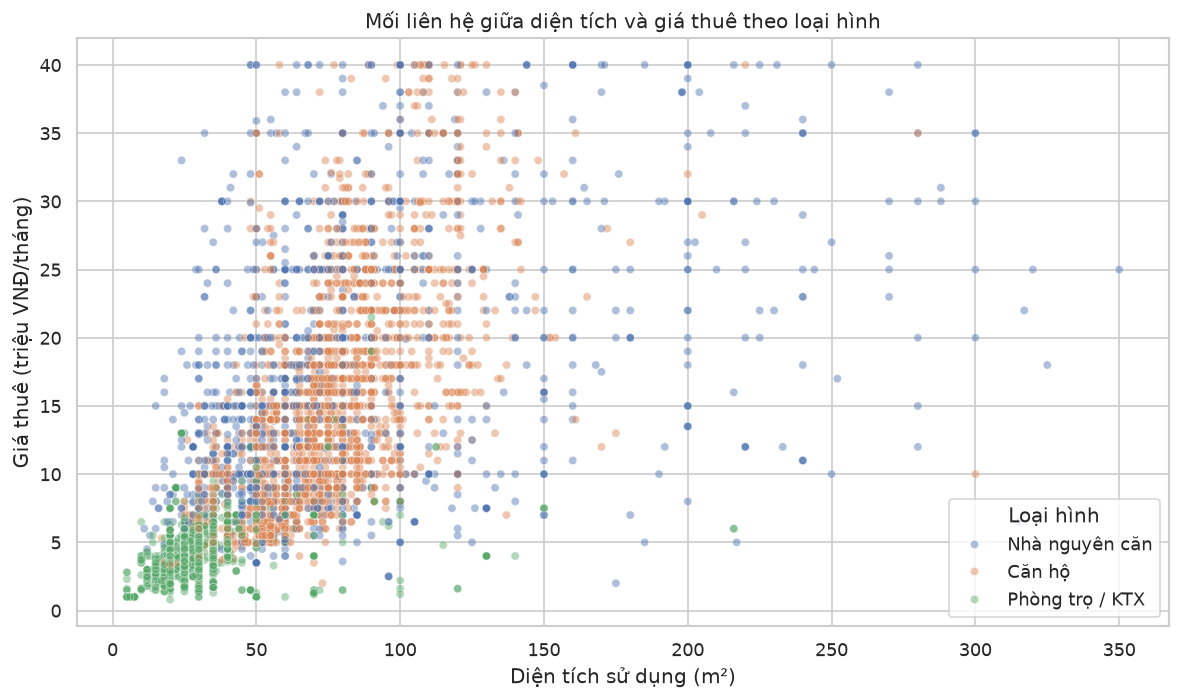

Tương quan Spearman toàn mẫu là **0.79**; trong từng loại hình: Căn hộ: rho=0.69; Nhà nguyên căn: rho=0.45; Phòng trọ / KTX: rho=0.38. Diện tích có thể giúp người thuê đánh giá giá trị sử dụng trên cùng ngân sách, nhưng các cụm khác nhau cho thấy cần so sánh thêm loại hình và khu vực. Chủ nhà có thể dùng tin cùng loại và diện tích gần nhau để rà mức giá chào; nền tảng có thể đề xuất các tin tương đồng thay vì chỉ sắp theo giá tổng. Hình hiển thị mẫu tối đa 6.000 điểm để giảm chồng lấp, hệ số tính trên toàn bộ mẫu; tương quan không chứng minh diện tích là nguyên nhân duy nhất của giá.

In [12]:
sample = eda.sample(min(6000, len(eda)), random_state=42)
rho = eda["dien_tich_m2"].corr(eda["gia_thue_trieu_thang"], method="spearman")
by_type_rho = eda.groupby("loai_hinh").apply(
    lambda g:g["dien_tich_m2"].corr(g["gia_thue_trieu_thang"], method="spearman"))
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample, x="dien_tich_m2", y="gia_thue_trieu_thang",
                hue="loai_hinh", alpha=.45, s=24, ax=ax)
ax.set(title="Mối liên hệ giữa diện tích và giá thuê theo loại hình",
       xlabel="Diện tích sử dụng (m²)", ylabel="Giá thuê (triệu VNĐ/tháng)")
ax.legend(title="Loại hình")
plt.tight_layout()
plt.show()
rhos = "; ".join(f"{k}: rho={v:.2f}" for k,v in by_type_rho.items())
display(Markdown(
    f"Tương quan Spearman toàn mẫu là **{rho:.2f}**; trong từng loại hình: {rhos}. Diện tích có thể giúp người "
    f"thuê đánh giá giá trị sử dụng trên cùng ngân sách, nhưng các cụm khác nhau cho thấy cần so sánh thêm loại hình "
    f"và khu vực. Chủ nhà có thể dùng tin cùng loại và diện tích gần nhau để rà mức giá chào; nền tảng có thể đề xuất "
    f"các tin tương đồng thay vì chỉ sắp theo giá tổng. Hình hiển thị mẫu tối đa 6.000 điểm để giảm chồng lấp, hệ số "
    f"tính trên toàn bộ mẫu; tương quan không chứng minh diện tích là nguyên nhân duy nhất của giá."
))

### Biểu đồ 7 - Số tin theo khu vực và loại hình

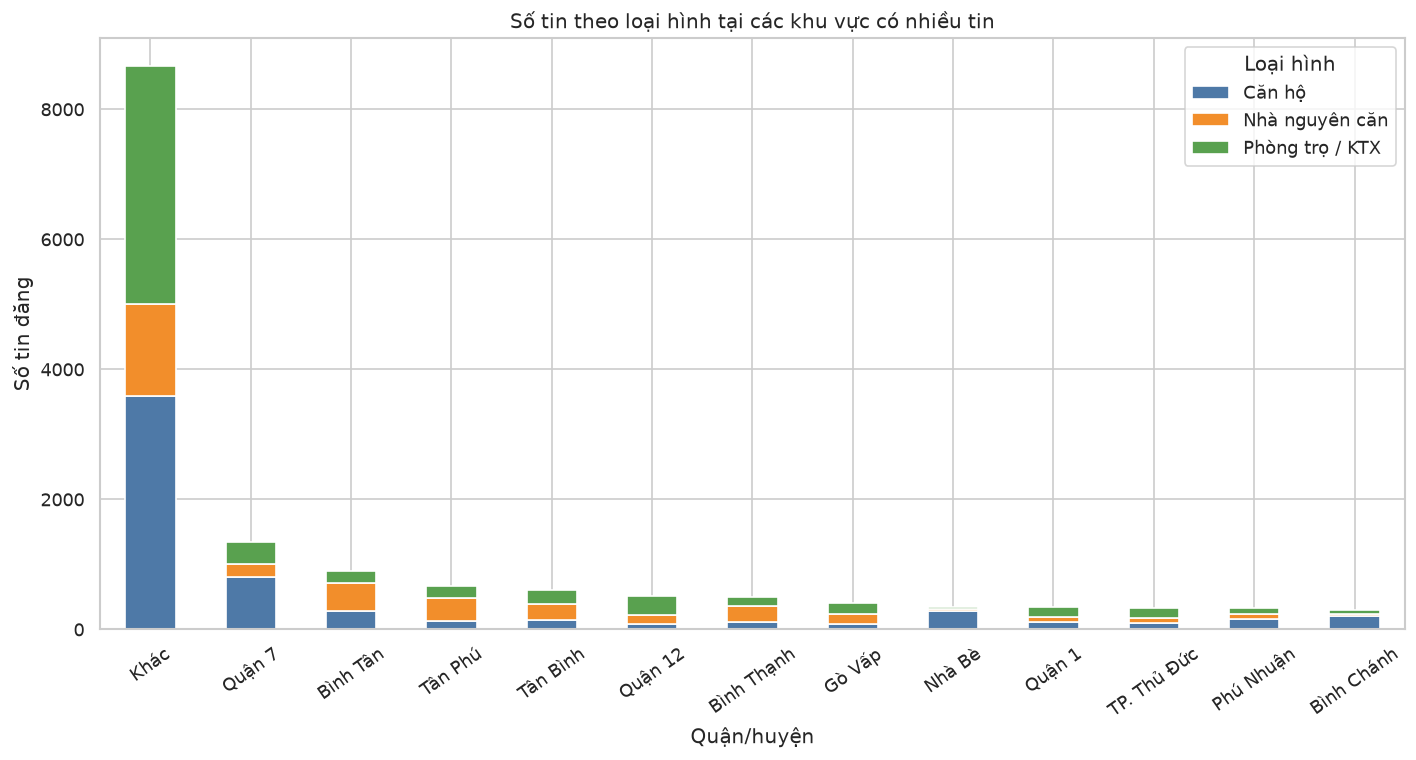

Quận 7 là khu vực định vị được có nhiều tin nhất (1,336); nhóm Khác cũng được giữ trong biểu đồ và chiếm 53.0% gold. Nhiều tin tạo thêm lựa chọn để sinh viên so sánh, đồng thời giúp nền tảng ưu tiên công cụ lọc và kiểm tra chất lượng tại khu vực có lượng cung lớn. Chủ nhà có thể xem cơ cấu loại hình để hiểu nhóm cạnh tranh đang hiện diện. Số tin phản ánh tập crawler thu thập chứ không phải tổng số phòng còn trống; khu ít tin có thể do nguồn cung hoặc do độ bao phủ định vị thấp. Tỷ lệ Khác lớn là hạn chế địa lý cần cải thiện trước khi dùng kết quả để phân bổ nguồn lực theo quận.

In [13]:
ct = pd.crosstab(eda["quan_huyen"], eda["loai_hinh"])
known = ct.drop(index="Khác", errors="ignore").sum(axis=1).sort_values(ascending=False)
show_districts = (["Khác"] if "Khác" in ct.index else []) + known.head(12).index.tolist()
ct_plot = ct.reindex(show_districts).fillna(0)
fig, ax = plt.subplots(figsize=(12, 6.5))
ct_plot.plot(kind="bar", stacked=True, ax=ax, color=["#4E79A7", "#F28E2B", "#59A14F"])
ax.set(title="Số tin theo loại hình tại các khu vực có nhiều tin",
       xlabel="Quận/huyện", ylabel="Số tin đăng")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Loại hình")
plt.tight_layout()
plt.show()
top = known.index[0]
display(Markdown(
    f"{top} là khu vực định vị được có nhiều tin nhất ({int(known.iloc[0]):,}); nhóm Khác cũng được giữ trong "
    f"biểu đồ và chiếm {eda['quan_huyen'].eq('Khác').mean():.1%} gold. Nhiều tin tạo thêm lựa chọn để sinh viên "
    f"so sánh, đồng thời giúp nền tảng ưu tiên công cụ lọc và kiểm tra chất lượng tại khu vực có lượng cung lớn. "
    f"Chủ nhà có thể xem cơ cấu loại hình để hiểu nhóm cạnh tranh đang hiện diện. Số tin phản ánh tập crawler thu "
    f"thập chứ không phải tổng số phòng còn trống; khu ít tin có thể do nguồn cung hoặc do độ bao phủ định vị thấp. "
    f"Tỷ lệ Khác lớn là hạn chế địa lý cần cải thiện trước khi dùng kết quả để phân bổ nguồn lực theo quận."
))

### Biểu đồ 8 - Giá thuê theo WC riêng, gác lửng và máy lạnh

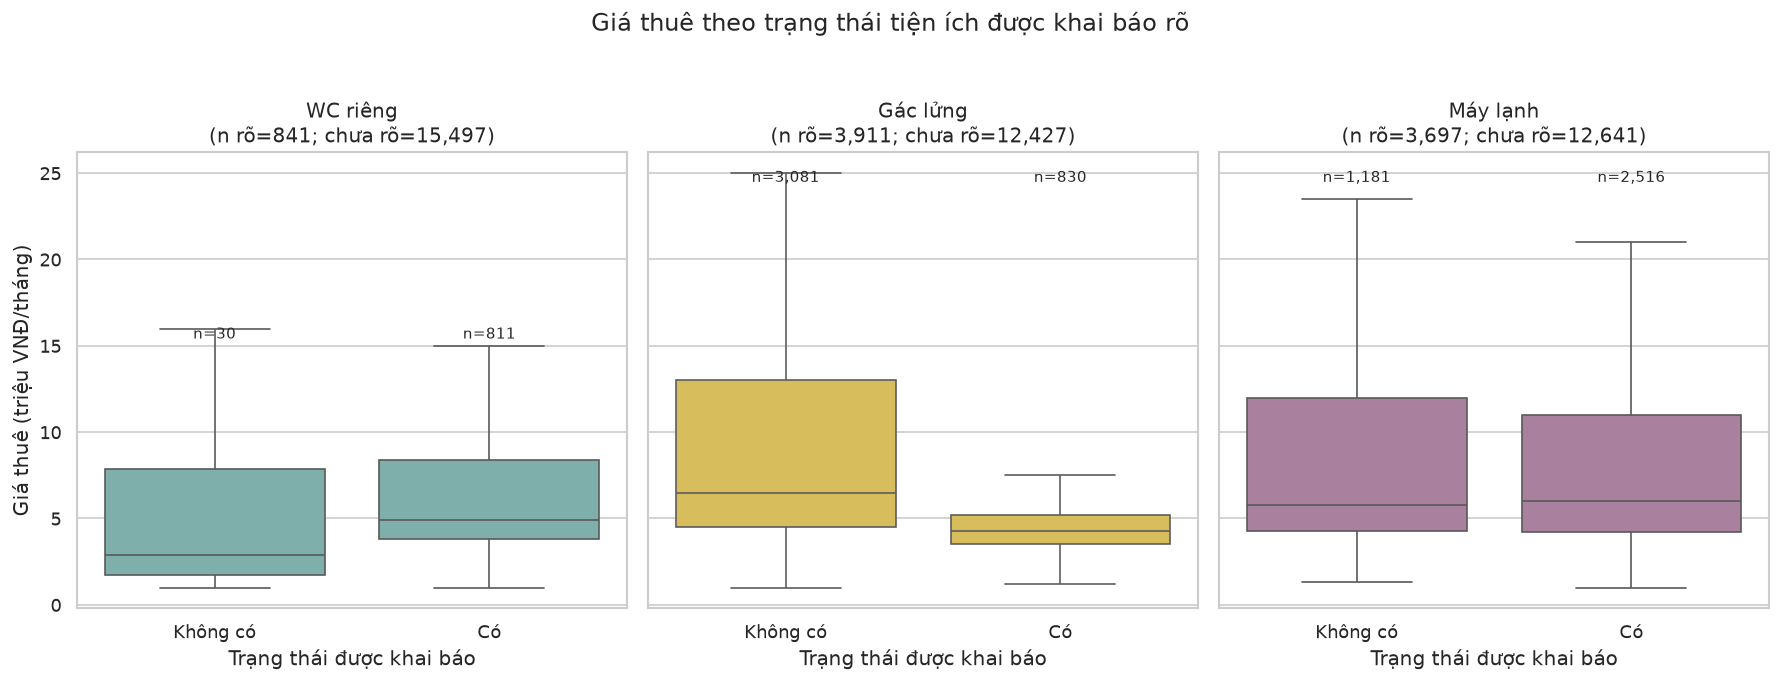

WC riêng: trung vị 4.90 triệu/tháng khi có (n=811) và 2.90 triệu khi không có (n=30), chênh +2.00 triệu (+69.0%); Gác lửng: trung vị 4.30 triệu/tháng khi có (n=830) và 6.50 triệu khi không có (n=3,081), chênh -2.20 triệu (-33.8%); Máy lạnh: trung vị 6.00 triệu/tháng khi có (n=2,516) và 5.80 triệu khi không có (n=1,181), chênh +0.20 triệu (+3.4%). Với sinh viên, các mức chênh giúp cân nhắc tiện ích nào đáng ưu tiên trong ngân sách; chủ nhà có thể xem đây là tín hiệu về sức cạnh tranh; nền tảng có thể cải thiện bộ lọc và khuyến khích khai báo rõ. Độ phủ trạng thái chỉ là 841 tin WC riêng, 3,911 tin gác lửng và 3,697 tin máy lạnh trên 16,338 bản ghi. Mẫu có thông tin có thể thiên về tin mô tả kỹ; loại hình, địa bàn và diện tích còn khác nhau giữa hai nhóm. Gold đã điền mặc định ở một số cột nên không dùng các giá trị đó như xác nhận; thiếu trong raw vẫn là chưa rõ. Chênh lệch không chứng minh tiện ích tự nó làm giá tăng.

In [14]:

amenity_specs = [
    ("has_wc_rieng", "WC riêng", "#76B7B2"),
    ("has_gac_lung", "Gác lửng", "#EDC948"),
    ("has_may_lanh", "Máy lạnh", "#B07AA1"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
amenity_results = {}
for ax, (column, label, color) in zip(axes, amenity_specs):
    observed = pd.to_numeric(eda[f"{column}_raw_observed"], errors="coerce")
    mask = observed.isin([0, 1])
    panel = pd.DataFrame({
        "gia": pd.to_numeric(eda.loc[mask, "gia_thue_trieu_thang"]),
        "trang_thai": observed.loc[mask].map({0: "Không có", 1: "Có"}),
    })
    stats = panel.groupby("trang_thai")["gia"].agg(n="count", median="median").reindex(["Không có", "Có"])
    amenity_results[column] = {"label": label, "stats": stats, "known_n": int(mask.sum())}
    sns.boxplot(data=panel, x="trang_thai", y="gia", order=["Không có", "Có"],
                color=color, showfliers=False, ax=ax)
    ax.set_title(f"{label}\n(n rõ={int(mask.sum()):,}; chưa rõ={int(observed.isna().sum()):,})")
    ax.set_xlabel("Trạng thái được khai báo")
    ax.set_ylabel("Giá thuê (triệu VNĐ/tháng)" if ax is axes[0] else "")
    for xpos, status in enumerate(["Không có", "Có"]):
        n = stats.loc[status, "n"]
        if pd.notna(n):
            ax.text(xpos, ax.get_ylim()[1] * .96, f"n={int(n):,}", ha="center", va="top", fontsize=9)
fig.suptitle("Giá thuê theo trạng thái tiện ích được khai báo rõ", y=1.03)
fig.tight_layout()
plt.show()

comparisons = []
for result in amenity_results.values():
    stats = result["stats"]
    no, yes = stats.loc["Không có"], stats.loc["Có"]
    difference = yes["median"] - no["median"]
    percent = difference / no["median"] * 100 if no["median"] else np.nan
    comparisons.append(
        f"{result['label']}: trung vị {yes['median']:.2f} triệu/tháng khi có (n={int(yes['n']):,}) "
        f"và {no['median']:.2f} triệu khi không có (n={int(no['n']):,}), "
        f"chênh {difference:+.2f} triệu ({percent:+.1f}%)"
    )
wc_n = amenity_results["has_wc_rieng"]["known_n"]
mezz_n = amenity_results["has_gac_lung"]["known_n"]
ac_n = amenity_results["has_may_lanh"]["known_n"]
display(Markdown(
    f"{'; '.join(comparisons)}. Với sinh viên, các mức chênh giúp cân nhắc tiện ích nào đáng ưu tiên "
    f"trong ngân sách; chủ nhà có thể xem đây là tín hiệu về sức cạnh tranh; nền tảng có thể cải thiện bộ lọc "
    f"và khuyến khích khai báo rõ. Độ phủ trạng thái chỉ là {wc_n:,} tin WC riêng, {mezz_n:,} tin gác lửng "
    f"và {ac_n:,} tin máy lạnh trên {len(eda):,} bản ghi. Mẫu có thông tin có thể thiên về tin mô tả kỹ; "
    f"loại hình, địa bàn và diện tích còn khác nhau giữa hai nhóm. Gold đã điền mặc định ở một số cột nên "
    f"không dùng các giá trị đó như xác nhận; thiếu trong raw vẫn là chưa rõ. Chênh lệch không chứng minh "
    f"tiện ích tự nó làm giá tăng."
))


### Biểu đồ 9 - Tương quan giá thuê và đặc trưng

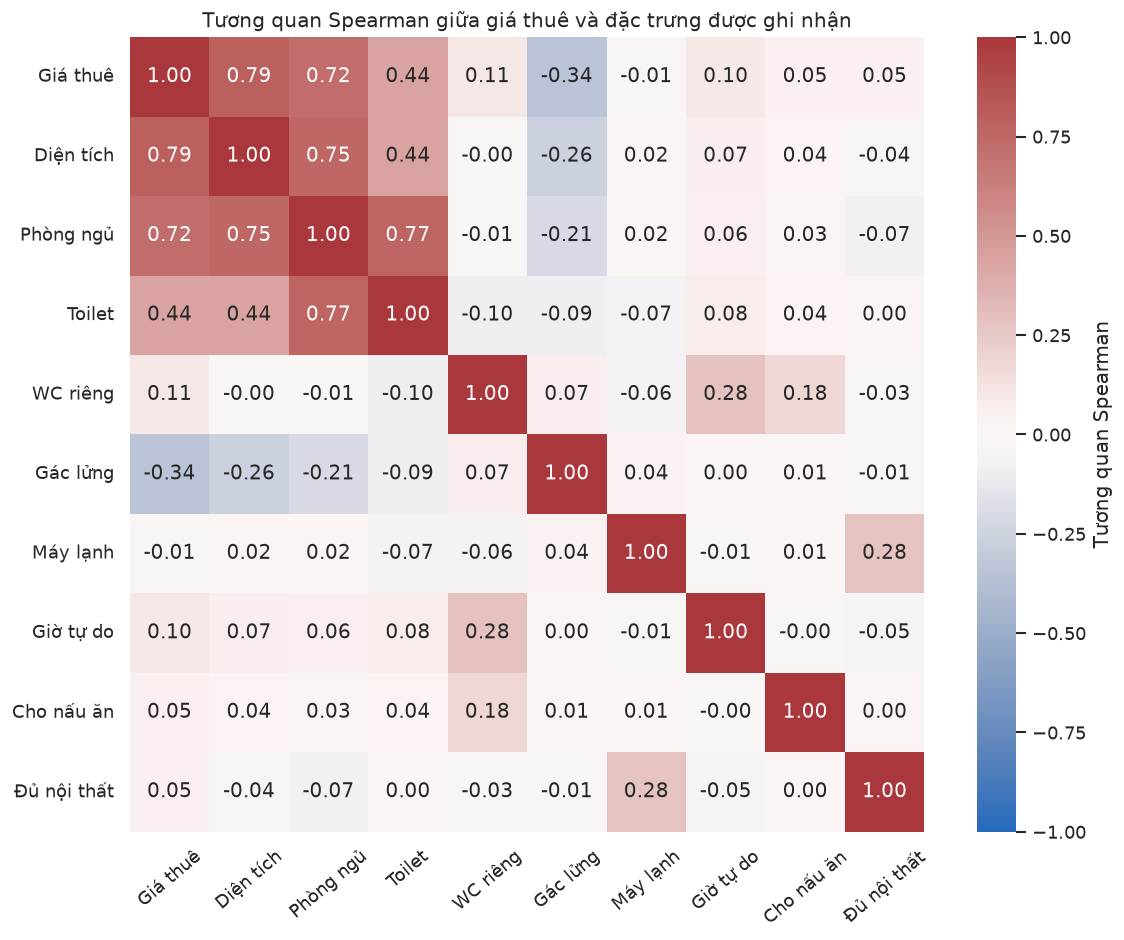

Trong các đặc trưng có dữ liệu tường minh, mối liên hệ đơn điệu mạnh nhất với giá theo trị tuyệt đối là **Diện tích** (rho=0.79). Heatmap giúp sàng lọc biến cần xem xét trong AVM; với người thuê và chủ nhà, nó gợi ý tiêu chí cần đối chiếu khi so sánh tin. Đơn giá/m² không đưa vào vì được tính trực tiếp từ giá và diện tích, gây rò rỉ mục tiêu nếu dự đoán giá. Phòng ngủ, toilet và tiện ích lấy từ raw tường minh để không biến giá trị gold đã điền thành quan sát; số mẫu từng cặp có thể khác nhau, và tương quan không chứng minh quan hệ nhân quả.

In [15]:
corr_data = pd.DataFrame({
    "Giá thuê": pd.to_numeric(eda["gia_thue_trieu_thang"], errors="coerce"),
    "Diện tích": pd.to_numeric(eda["dien_tich_m2"], errors="coerce"),
    "Phòng ngủ": pd.to_numeric(eda["so_phong_ngu_raw_observed"], errors="coerce"),
    "Toilet": pd.to_numeric(eda["so_toilet_raw_observed"], errors="coerce"),
    "WC riêng": pd.to_numeric(eda["has_wc_rieng_raw_observed"], errors="coerce"),
    "Gác lửng": pd.to_numeric(eda["has_gac_lung_raw_observed"], errors="coerce"),
    "Máy lạnh": pd.to_numeric(eda["has_may_lanh_raw_observed"], errors="coerce"),
    "Giờ tự do": pd.to_numeric(eda["gio_tu_do_raw_observed"], errors="coerce"),
    "Cho nấu ăn": pd.to_numeric(eda["cho_nau_an_raw_observed"], errors="coerce"),
    "Đủ nội thất": pd.to_numeric(eda["is_full_furniture_raw_observed"], errors="coerce"),
})
corr = corr_data.corr(method="spearman", min_periods=30)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, cbar_kws={"label": "Tương quan Spearman"}, ax=ax)
ax.set(title="Tương quan Spearman giữa giá thuê và đặc trưng được ghi nhận")
ax.tick_params(axis="x", rotation=40)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()
rc = corr["Giá thuê"].drop("Giá thuê").dropna()
feature = rc.abs().idxmax() if len(rc) else "không đủ quan sát"
value = rc.get(feature, np.nan)
display(Markdown(
    f"Trong các đặc trưng có dữ liệu tường minh, mối liên hệ đơn điệu mạnh nhất với giá theo trị tuyệt đối là "
    f"**{feature}** (rho={value:.2f}). Heatmap giúp sàng lọc biến cần xem xét trong AVM; với người thuê và "
    f"chủ nhà, nó gợi ý tiêu chí cần đối chiếu khi so sánh tin. Đơn giá/m² không đưa vào vì được tính trực tiếp "
    f"từ giá và diện tích, gây rò rỉ mục tiêu nếu dự đoán giá. Phòng ngủ, toilet và tiện ích lấy từ raw tường minh "
    f"để không biến giá trị gold đã điền thành quan sát; số mẫu từng cặp có thể khác nhau, và tương quan không "
    f"chứng minh quan hệ nhân quả."
))

### Biểu đồ 10 - Treemap tương tác theo loại hình và khu vực

In [16]:
tree = eda.loc[eda["quan_huyen"].ne("Khác")].groupby(
    ["loai_hinh","quan_huyen"], as_index=False).agg(
        so_tin=("id","count"), gia_trung_vi=("gia_thue_trieu_thang","median"),
        don_gia_trung_vi=("don_gia_nghin_m2","median"))
fig = px.treemap(tree, path=["loai_hinh","quan_huyen"], values="so_tin",
    color="gia_trung_vi", color_continuous_scale="Tealrose",
    hover_data={"so_tin":True,"gia_trung_vi":":.2f","don_gia_trung_vi":":.1f"},
    title="Quy mô tin và giá trung vị theo phân khúc, quận/huyện",
    labels={"so_tin":"Số tin","gia_trung_vi":"Giá thuê trung vị (triệu VNĐ/tháng)",
            "don_gia_trung_vi":"Đơn giá trung vị (nghìn VNĐ/m²/tháng)"})
fig.update_layout(margin=dict(t=55,l=10,r=10,b=10),
                  coloraxis_colorbar_title="Triệu VNĐ/tháng")
fig.show()
big = tree.loc[tree["so_tin"].idxmax()]
display(Markdown(
    f"Diện tích ô biểu thị số tin, màu biểu thị giá trung vị; ô nhiều tin nhất là {big['loai_hinh']} tại "
    f"{big['quan_huyen']} (n={int(big['so_tin']):,}, giá trung vị {big['gia_trung_vi']:.2f} triệu/tháng). "
    f"Sinh viên có thể khám phá nhanh các lựa chọn thuộc cùng loại hình ở nhiều quận; chủ nhà có thể xác định "
    f"nhóm cạnh tranh phù hợp; nền tảng có thể nhận diện khu vực dữ liệu dày hoặc mỏng. Rê chuột để xem số tin, "
    f"giá và đơn giá. Nhóm Khác bị loại khỏi treemap vì không có địa bàn đáng tin cậy; hình chỉ phản ánh phần mẫu "
    f"định vị được và giá tin đăng, không phải giao dịch thực tế."
))

Diện tích ô biểu thị số tin, màu biểu thị giá trung vị; ô nhiều tin nhất là Căn hộ tại Quận 7 (n=801, giá trung vị 15.50 triệu/tháng). Sinh viên có thể khám phá nhanh các lựa chọn thuộc cùng loại hình ở nhiều quận; chủ nhà có thể xác định nhóm cạnh tranh phù hợp; nền tảng có thể nhận diện khu vực dữ liệu dày hoặc mỏng. Rê chuột để xem số tin, giá và đơn giá. Nhóm Khác bị loại khỏi treemap vì không có địa bàn đáng tin cậy; hình chỉ phản ánh phần mẫu định vị được và giá tin đăng, không phải giao dịch thực tế.

### Biểu đồ 11 - Nhãn thời gian cập nhật tương đối

Trường ngày chỉ có nhãn kiểu “Cập nhật: 2 tháng trước”, không có ngày chụp crawler cố định. Hình này đánh giá độ mới tương đối của kho tin, không chuyển nhãn thành ngày lịch và không suy diễn xu hướng giá theo thời gian.

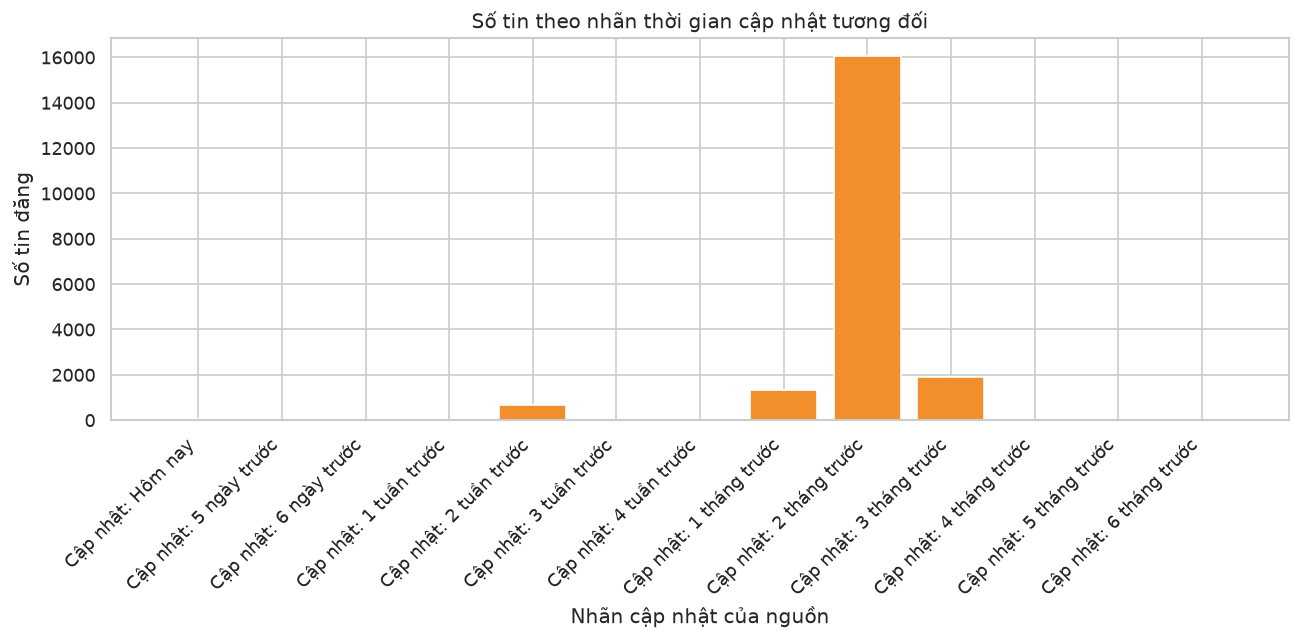

Nhãn phổ biến nhất là **Cập nhật: 2 tháng trước**, xuất hiện ở 16,040 tin (80.2% raw). Về trải nghiệm thuê, người tìm nhà nên xác nhận tin còn hiệu lực, giá và phí trước khi đi xem; nền tảng có thể nhắc chủ đăng xác thực tin cũ hoặc hạ ưu tiên hiển thị; chủ nhà cập nhật thường xuyên giúp giảm liên hệ không còn nhu cầu. Đây là tín hiệu vận hành về độ mới của dữ liệu, không phải xu hướng thị trường: nhãn thời lượng tương đối thiếu thời điểm chụp chính xác, nên không thể lập chuỗi giá theo tháng lịch.

In [17]:
dates = raw["date_raw"].replace("", "Không có thông tin").value_counts()
def sort_age(label):
    if label == "Không có thông tin": return (9999, 0)
    text = str(label).lower()
    if "hôm nay" in text: return (0, 0)
    m = re.search(r"(\d+)\s*(ngày|tuần|tháng)", text)
    if not m: return (9998, 0)
    factor = {"ngày":1,"tuần":7,"tháng":30}[m.group(2)]
    return (int(m.group(1))*factor, int(m.group(1)))
dates = dates.reindex(sorted(dates.index, key=sort_age))
fig, ax = plt.subplots(figsize=(11,5.5))
ax.bar(range(len(dates)), dates.values, color="#F28E2B")
ax.set_xticks(range(len(dates)))
ax.set_xticklabels(dates.index, rotation=45, ha="right")
ax.set(title="Số tin theo nhãn thời gian cập nhật tương đối",
       xlabel="Nhãn cập nhật của nguồn", ylabel="Số tin đăng")
plt.tight_layout()
plt.show()
age_label, age_n = dates.idxmax(), int(dates.max())
display(Markdown(
    f"Nhãn phổ biến nhất là **{age_label}**, xuất hiện ở {age_n:,} tin ({age_n/len(raw):.1%} raw). "
    f"Về trải nghiệm thuê, người tìm nhà nên xác nhận tin còn hiệu lực, giá và phí trước khi đi xem; nền tảng "
    f"có thể nhắc chủ đăng xác thực tin cũ hoặc hạ ưu tiên hiển thị; chủ nhà cập nhật thường xuyên giúp giảm liên "
    f"hệ không còn nhu cầu. Đây là tín hiệu vận hành về độ mới của dữ liệu, không phải xu hướng thị trường: nhãn "
    f"thời lượng tương đối thiếu thời điểm chụp chính xác, nên không thể lập chuỗi giá theo tháng lịch."
))

## 6. Feature engineering và chuẩn bị mô hình

Biến mục tiêu là gia_thue_trieu_thang. Biến đầu vào tiềm năng gồm diện tích, loại hình, địa bàn, số phòng và tiện ích. don_gia_nghin_m2 phục vụ so sánh mô tả nhưng không đưa vào mô hình dự đoán giá vì được tính trực tiếp từ giá và diện tích.

Các đặc trưng gold được điền theo quy tắc nghiệp vụ cần được nhận diện là giá trị suy diễn. Khi xây mô hình, nên giữ cờ nguồn hoặc cờ thiếu ban đầu để đánh giá ảnh hưởng của việc điền. Hai nhóm mô hình dự kiến là hồi quy tuyến tính/Ridge làm baseline và Random Forest hoặc Gradient Boosting để kiểm tra quan hệ phi tuyến. Chia train/test trước khi fit imputer, encoder hay scaler; mọi phép fit chỉ dùng tập train. Logistic Regression chỉ phù hợp nếu xây thêm bài toán phân loại phân khúc.

## 7. Kết luận và giới hạn

Giá thuê thay đổi theo phân khúc, diện tích và khu vực; tiện ích có thể hỗ trợ so sánh nhưng độ phủ khai báo còn hạn chế. Sinh viên có thể dùng phân bố theo phân khúc và địa bàn để lập ngân sách; chủ nhà có thể so sánh với sản phẩm tương đồng; nền tảng có thể cải thiện chất lượng khai báo và xác nhận tin cũ.

Dữ liệu phản ánh giá chào trong tin đăng, không bảo đảm là giá giao dịch hoặc phòng còn trống. Quận/huyện Khác chiếm tỷ lệ lớn; tiện ích còn thiếu và một số đặc trưng trong gold được điền theo giả định nghiệp vụ; ngày cập nhật chỉ là nhãn tương đối. Vì vậy, các so sánh mô tả không phải tác động nhân quả hay giá chuẩn đã kiểm soát mọi khác biệt.